# 2. Open dynamics

The modes can lose energy, heat up or diffuse. gbcs takes the Lindblad master equation

$$\frac{\partial\hat\varrho}{\partial\tau} = -i[\hat H,\hat\varrho] + \sum_{ab} B^{ab}\left(\hat r_a\hat\varrho\,\hat r_b - \tfrac12\{\hat r_b\hat r_a, \hat\varrho\}\right) + \dots$$

with a Hermitian, positive $2n\times2n$ matrix $B$. In phase space $B$ gives a drift $E = -\mathrm{Im}\,B$ and a diffusion $D = 2\Omega\,\mathrm{Re}B\,\Omega^{\mathsf T}$ (Table III). Two further terms are available:

- a linear drive $d$ of the modes, which enters the first moments as $\Omega d$ (for a coherent input $\alpha_{in}$ on a cavity of linewidth $\kappa$, $d = |\alpha_{in}|\sqrt{2\kappa}\,(\cos\phi_d, \sin\phi_d)$);
- qubit dephasing at rate $\Gamma_z$ per qubit, the decay rate of each qubit's coherence.

All of this goes into a `Decoherence` object.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from gbcs import Quantum_State, Hamiltonian, Decoherence
from gbcs import Wigner_Functions

I2 = np.eye(2)
OMEGA = np.array([[0., 1.], [-1., 0.]])
SIGMA_X = np.array([[0., 1.], [1., 0.]])

def show_wigner(ax, W, x, p, title):
    limit = np.max(np.abs(W))
    ax.imshow(W, origin='lower', extent=[x[0], x[-1], p[0], p[-1]], cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_xlabel('$x$')
    ax.set_title(title)

## The Decoherence object

$B$ can be written in the canonical basis $(\hat x, \hat p)$ or in the ladder basis $(\hat a, \hat a^\dagger)$. Cavity loss $\kappa\,\mathcal D[\hat a]$ is $B = \kappa\begin{pmatrix}0&1\\0&0\end{pmatrix}$ in the ladder basis, which gives $E = \tfrac\kappa2\Omega$ and $D = \kappa\mathbb 1$. Position diffusion $\Gamma_x\mathcal D[\hat x]$ is $B = \Gamma_x\begin{pmatrix}1&0\\0&0\end{pmatrix}$ in the canonical basis.

In [2]:
kappa = 1.0
loss = Decoherence(1, 1, 'Ladder', kappa*np.array([[0., 1.], [0., 0.]]))
print('E =\n', loss.E_mat.round(12), '\nD =\n', loss.D_mat.round(12))

same_loss = Decoherence(1, 1, 'Canonical', (kappa/2)*(I2 - 1j*OMEGA))
print('canonical form agrees:', np.allclose(loss.E_mat, same_loss.E_mat), np.allclose(loss.D_mat, same_loss.D_mat))

E =
 [[-0.   0.5]
 [-0.5 -0. ]] 
D =
 [[1. 0.]
 [0. 1.]]
canonical form agrees: True True


## A driven, lossy cavity

A coherent state in a cavity with loss decays towards the vacuum at rate $\kappa/2$ in amplitude. With a drive, it settles into the coherent state set by the balance of drive and loss. The covariance stays at the vacuum value throughout.

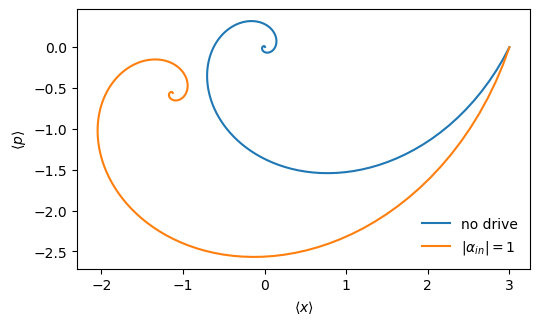

In [3]:
H_cav = Hamiltonian(1, 1)
H_cav.Initialize_Constant_Hamiltonians([I2], [np.zeros((2, 1))], np.array([0.0]))
tau = np.linspace(0, 12, 241)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
for alpha_in, label in ((0.0, 'no drive'), (1.0, r'$|\alpha_{in}| = 1$')):
    d = alpha_in*np.sqrt(2*kappa)*np.array([[1.], [0.]])
    cavity = Decoherence(1, 1, 'Ladder', kappa*np.array([[0., 1.], [0., 0.]]), d_vec=d)
    G = Quantum_State(1, 1)
    G.Initialize_Gaussian_State(np.array([[3.], [0.]]), I2, np.ones((1, 1)))
    G.Open_Dynamics_Numerical(H_cav, cavity, tau)
    ax.plot(G.r_t[:, 0, 0].real, G.r_t[:, 1, 0].real, label=label)
ax.set_aspect('equal')
ax.set_xlabel(r'$\langle x\rangle$')
ax.set_ylabel(r'$\langle p\rangle$')
ax.legend(frameon=False)
plt.tight_layout()

## Diffusion in a Stern–Gerlach interferometer

The interferometer of tutorial 1, now with position diffusion $\Gamma_x$. Diffusion leaves the branches on the same trajectories but makes $\bar r_{+-}$ complex. As a result, the contrast no longer comes back fully at recombination: $\mathcal C(2\pi) = 6\pi f_q^2\Gamma_x$, whatever the initial state.

In [4]:
f_q, f_u, Gamma_x = 2.0, 0.5, 0.05
H_sg = Hamiltonian(1, 1)
H_sg.Initialize_Constant_Hamiltonians([I2], [np.array([[f_u], [0.]]), np.array([[f_q], [0.]])], np.array([0.0]))
diffusion = Decoherence(1, 1, 'Canonical', Gamma_x*np.diag([1., 0.]))

tau_sg = np.linspace(0, 2*np.pi, 201)
unitary, diffusive = Quantum_State(1, 1), Quantum_State(1, 1)
for G in (unitary, diffusive):
    G.Initialize_Gaussian_State(np.zeros((2, 1)), I2, np.ones((2, 2))/2)
unitary.Unitary_Dynamics_Numerical(H_sg, tau_sg)
diffusive.Open_Dynamics_Numerical(H_sg, diffusion, tau_sg)

print(f'C(2 pi) = {diffusive.C_JK_t[-1, 1, 0].real:.6f},  6 pi f_q^2 Gamma_x = {6*np.pi*f_q**2*Gamma_x:.6f}')
print('r_+-(2 pi) =', diffusive.r_JK_t[-1, 1, 0, :, 0].round(4))

C(2 pi) = 3.769911,  6 pi f_q^2 Gamma_x = 3.769911
r_+-(2 pi) = [ 0.-0.j     -0.-0.6283j]


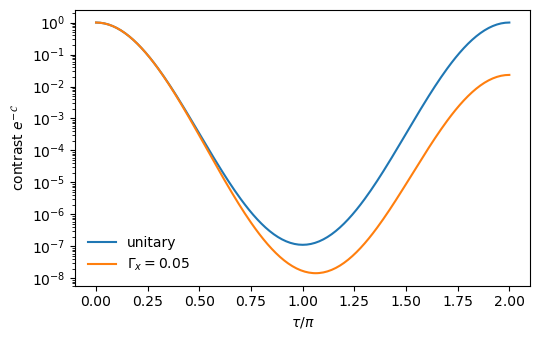

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.semilogy(tau_sg/np.pi, np.exp(-unitary.C_JK_t[:, 1, 0]), label='unitary')
ax.semilogy(tau_sg/np.pi, np.exp(-diffusive.C_JK_t[:, 1, 0].real), label=rf'$\Gamma_x = {Gamma_x}$')
ax.set_xlabel(r'$\tau/\pi$')
ax.set_ylabel(r'contrast $e^{-\mathcal{C}}$')
ax.legend(frameon=False)
plt.tight_layout()

Qubit dephasing simply adds $\Gamma_z\tau$ to $\mathcal C$:

In [6]:
dephased = Quantum_State(1, 1)
dephased.Initialize_Gaussian_State(np.zeros((2, 1)), I2, np.ones((2, 2))/2)
dephased.Open_Dynamics_Numerical(H_sg, Decoherence(1, 1, 'Canonical', Gamma_x*np.diag([1., 0.]), Gamma_z=np.array([0.1])), tau_sg)
extra = dephased.C_JK_t[-1, 1, 0].real - diffusive.C_JK_t[-1, 1, 0].real
print(f'extra C at 2 pi: {extra:.6f}   (Gamma_z 2 pi = {0.1*2*np.pi:.6f})')

extra C at 2 pi: 0.628319   (Gamma_z 2 pi = 0.628319)


## Dispersive readout with a parametric amplifier

Example 1 of the paper. A qubit shifts the frequency of a cavity, $H_j = \lambda\sigma_x + j\mu\mathbb 1$, where $\lambda\sigma_x$ is the squeezing of a parametric amplifier. The cavity is driven and loses photons at rate $\kappa$. The two branches settle into two squeezed pointer states, and the qubit coherence decays at a rate that starts at zero and reaches a steady value once the pointer states have formed.

In [7]:
mu, lam, alpha_in, phi_d = 0.4, 0.3, 1.8, 0.0
H_ro = Hamiltonian(1, 1)
H_ro.Initialize_Constant_Hamiltonians([lam*SIGMA_X, mu*I2], [np.zeros((2, 1)), np.zeros((2, 1))], np.array([0.0]))
d = alpha_in*np.sqrt(2*kappa)*np.array([[np.cos(phi_d)], [np.sin(phi_d)]])
readout_noise = Decoherence(1, 1, 'Ladder', kappa*np.array([[0., 1.], [0., 0.]]), d_vec=d)

tau_ro = np.linspace(0, 20, 401)
ro = Quantum_State(1, 1)
ro.Initialize_Gaussian_State(np.zeros((2, 1)), I2, np.ones((2, 2))/2)
ro.Open_Dynamics_Numerical(H_ro, readout_noise, tau_ro, solver='linear')

rate = np.gradient(ro.C_JK_t[:, 1, 0].real, tau_ro)
print('pointer states:', ro.r_JK_t[-1, 1, 1, :, 0].real.round(3), ro.r_JK_t[-1, 0, 0, :, 0].real.round(3))
print(f'steady dephasing rate: {rate[-1]:.4f}')

pointer states: [-3.182 -1.591] [ 3.182 -1.591]
steady dephasing rate: 2.7202


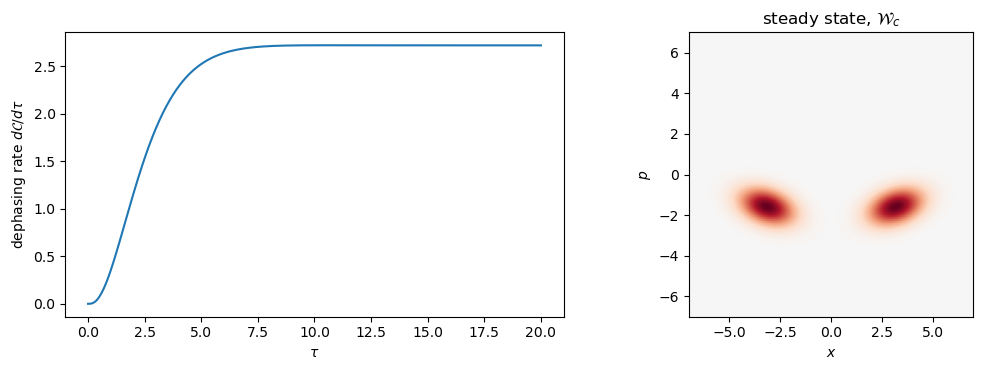

In [8]:
grid, x, p, _, _ = Wigner_Functions.Create_r_tilde_array(ro, 2.0, 0, 151)
W_c = Wigner_Functions.Wigner_Sum_Diagonal(ro, len(tau_ro) - 1, grid)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(tau_ro, rate)
axes[0].set_xlabel(r'$\tau$')
axes[0].set_ylabel(r'dephasing rate $d\mathcal{C}/d\tau$')
show_wigner(axes[1], W_c, x, p, r'steady state, $\mathcal{W}_c$')
axes[1].set_ylabel('$p$')
plt.tight_layout()

For constant Hamiltonians, use `solver='linear'`. It is faster and more accurate than `solver='ode'`. Time-dependent Hamiltonians (`Initialize_Time_Dep_Hamiltonian`) are not validated when the modes are coupled to the qubits, and the library warns when they are used.